# 1. Import

In [1]:
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    StackingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
)
from xgboost import XGBClassifier

# ต้องติดตั้งก่อนถ้ายังไม่มี: pip install imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 2. Load Prepared Data

In [2]:
data = joblib.load("../data/prepared_data.pkl")

# ใช้ X_train/X_test แบบ non-scaled สำหรับโมเดลนี้ทั้งหมด เพราะ
# RF / AdaBoost / XGBoost เป็น tree-based ไม่ไวต่อ scale
X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Train target distribution: {y_train.value_counts(normalize=True).to_dict()}")

X_train: (79567, 45), X_test: (19773, 45)
Train target distribution: {0: 0.8860080183995878, 1: 0.11399198160041223}


# 3. Define Base Models (แก้ไข — ใช้ SMOTE แทนวิธีถ่วงน้ำหนักแบบเดิม)

**เดิม** ใช้ 3 วิธีจัดการ imbalance ที่ต่างกันในแต่ละโมเดล (`class_weight` ของ RF, `sample_weight` ของ AdaBoost, `scale_pos_weight` ของ XGBoost) ซึ่งซับซ้อนและเคยชนกัน จนเกิดบั๊กมาแล้วหลายจุด (AdaBoost แตกกิ่งแย่กว่าสุ่มเดา, Stacking พังเพราะ scale ปนกัน)

**แก้ไข**: ใช้ **SMOTE** (Synthetic Minority Over-sampling) สร้างตัวอย่างสังเคราะห์ของ class ส่วนน้อย (`readmitted=1`) เพิ่มใน training set จนสมดุล 50/50 แทน — ทำที่จุดเดียว ทุกโมเดลได้ประโยชน์เหมือนกัน ไม่ต้องพึ่งกลไกเฉพาะของแต่ละโมเดลที่เสี่ยงชนกันอีก

⚠️ **สำคัญมาก**: ห้ามทำ SMOTE ก่อน train/test split หรือก่อน cross-validation เด็ดขาด เพราะตัวอย่างสังเคราะห์จะถูกสร้างจากข้อมูลใน validation fold ไปด้วย ทำให้เกิด data leakage (โมเดลเห็นข้อมูลที่ "คล้าย" กับสิ่งที่จะทดสอบ) จึงต้องห่อ SMOTE เข้ากับแต่ละโมเดลเป็น `imblearn.pipeline.Pipeline` แทนการ resample `X_train` ตรงๆ ครั้งเดียว — วิธีนี้ทำให้ SMOTE ถูกเรียกใหม่ทุกครั้งที่มีการ fit บนแต่ละ fold ของ cross-validation (ทั้งตอน `RandomizedSearchCV` และตอน `StackingClassifier` สร้าง out-of-fold predictions) โดยใช้เฉพาะข้อมูลของ fold นั้นเท่านั้น

In [3]:
rf_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)),
])

# max_depth=3 ให้ AdaBoost มีความสามารถจับ pattern มากกว่า decision stump (depth=1)
adaboost_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("adaboost", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=200,
        learning_rate=0.3,
        random_state=42,
    )),
])

xgb_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgboost", XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        eval_metric="logloss", random_state=42, n_jobs=-1,
    )),
])

# 4. Hyperparameter Tuning

ใช้ `RandomizedSearchCV` หา hyperparameter ที่ดีที่สุดสำหรับ RF และ XGBoost โดยใช้ `average_precision` เป็น scoring metric (เหมาะกับ imbalance มากกว่า accuracy/roc_auc) — tune ผ่าน `ImbPipeline` เพื่อให้ SMOTE ถูก apply ใหม่ในทุก fold ระหว่างการ tune ด้วย (ไม่ใช่ tune บนข้อมูลที่ SMOTE ไปแล้วครั้งเดียว)

**แก้ไข**: จำกัด `max_depth` ไม่ให้เป็น `None` (ไม่จำกัดความลึก) เพราะเสี่ยง overfit ง่ายกับข้อมูลจำนวนมากที่ SMOTE เพิ่มเข้ามาด้วย

⚠️ ใช้เวลารันนานพอสมควร ถ้าต้องการรันเร็วขึ้นให้ลด `n_iter` หรือ `cv` ลง

In [4]:
rf_param_dist = {
    "rf__n_estimators": [200, 300, 500],
    "rf__max_depth": [8, 12, 16],  # ไม่ใส่ None กัน overfit
    "rf__min_samples_leaf": [1, 2, 5],
}

rf_search = RandomizedSearchCV(
    rf_pipeline,
    rf_param_dist,
    n_iter=10,
    cv=3,
    scoring="average_precision",
    n_jobs=-1,
    random_state=42,
)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print("Best RF average_precision (CV):", rf_search.best_score_)
rf_pipeline = rf_search.best_estimator_

Best RF params: {'rf__n_estimators': 200, 'rf__min_samples_leaf': 5, 'rf__max_depth': 16}
Best RF average_precision (CV): 0.1389735808373246


In [5]:
xgb_param_dist = {
    "xgboost__n_estimators": [200, 300, 500],
    "xgboost__max_depth": [4, 6, 8],
    "xgboost__learning_rate": [0.01, 0.05, 0.1],
    "xgboost__subsample": [0.7, 0.9, 1.0],
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    xgb_param_dist,
    n_iter=10,
    cv=3,
    scoring="average_precision",
    n_jobs=-1,
    random_state=42,
)
xgb_search.fit(X_train, y_train)
print("Best XGBoost params:", xgb_search.best_params_)
print("Best XGBoost average_precision (CV):", xgb_search.best_score_)
xgb_pipeline = xgb_search.best_estimator_

Best XGBoost params: {'xgboost__subsample': 0.9, 'xgboost__n_estimators': 500, 'xgboost__max_depth': 6, 'xgboost__learning_rate': 0.1}
Best XGBoost average_precision (CV): 0.14845896417510765


# 5. Build Stacking Classifier

In [6]:
# Base learners: RF, AdaBoost, XGBoost (ทุกตัวห่อด้วย SMOTE ผ่าน ImbPipeline แล้ว)
# Meta learner: Logistic Regression
# cv=5 -> ใช้ 5-fold cross-validation ตอนสร้าง out-of-fold predictions สำหรับ
# เทรน meta-learner — SMOTE จะถูก apply ใหม่ในแต่ละ fold โดยอัตโนมัติเพราะ base
# estimators เป็น ImbPipeline ไม่ใช่โมเดลตรงๆ
#
# หมายเหตุ: out-of-fold predictions ที่ป้อนให้ meta-learner ยังคงตรงกับ y_train
# ที่ไม่ได้ SMOTE (สัดส่วน class เดิม ~11%) จึงยังต้องใช้ class_weight="balanced"
# ที่ตัว LogisticRegression เอง
#
# ใส่ passthrough=True ให้ meta-learner เห็นทั้ง prediction ของ 3 base models และ
# ฟีเจอร์ดิบด้วย — ฟีเจอร์ดิบมีสเกลต่างกันมาก (เช่น time_in_hospital เทียบกับ
# prediction ช่วง 0-1) จึงต้องห่อ final_estimator ด้วย
# Pipeline(StandardScaler -> LogisticRegression) กันไม่ให้ฟีเจอร์สเกลใหญ่ครอบงำ
# จนโมเดลพัง (เคยเกิดปัญหานี้มาก่อนตอนไม่ scale)
estimators = [
    ("rf", rf_pipeline),
    ("adaboost", adaboost_pipeline),
    ("xgboost", xgb_pipeline),
]

scaled_meta_learner = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=scaled_meta_learner,
    cv=5,
    n_jobs=-1,
    passthrough=True,
)

print("Training stacking ensemble (RF + AdaBoost + XGBoost -> LogisticRegression)...")
stacking_model.fit(X_train, y_train)
print("Training complete.")

Training stacking ensemble (RF + AdaBoost + XGBoost -> LogisticRegression)...
Training complete.


# 6. Evaluate (threshold = 0.5 ค่าเริ่มต้น)

In [7]:
def evaluate(name, model, X_te, y_te, threshold=0.5):
    y_proba = model.predict_proba(X_te)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    print(f"\n--- {name} (threshold={threshold:.3f}) ---")
    print(f"Accuracy : {accuracy_score(y_te, y_pred):.4f}")
    print(f"Precision: {precision_score(y_te, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_te, y_pred):.4f}")
    print(f"F1-score : {f1_score(y_te, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_te, y_proba):.4f}")
    print(f"PR-AUC   : {average_precision_score(y_te, y_proba):.4f}")
    print("Confusion matrix:")
    print(confusion_matrix(y_te, y_pred))
    print(classification_report(y_te, y_pred, digits=4))

print("================ Fitting individual base models for comparison ================")
rf_pipeline.fit(X_train, y_train)
adaboost_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

evaluate("Random Forest (+SMOTE)", rf_pipeline, X_test, y_test)
evaluate("AdaBoost (+SMOTE)", adaboost_pipeline, X_test, y_test)
evaluate("XGBoost (+SMOTE)", xgb_pipeline, X_test, y_test)
evaluate("Stacking (RF+AdaBoost+XGBoost -> LogisticRegression, passthrough)", stacking_model, X_test, y_test)

================ Fitting individual base models for comparison ================

--- Random Forest (+SMOTE) (threshold=0.500) ---
Accuracy : 0.8009
Precision: 0.1591
Recall   : 0.1760
F1-score : 0.1672
ROC-AUC  : 0.5857
PR-AUC   : 0.1430
Confusion matrix:
[[15442  2087]
 [ 1849   395]]
              precision    recall  f1-score   support

           0     0.8931    0.8809    0.8870     17529
           1     0.1591    0.1760    0.1672      2244

    accuracy                         0.8009     19773
   macro avg     0.5261    0.5285    0.5271     19773
weighted avg     0.8098    0.8009    0.8053     19773


--- AdaBoost (+SMOTE) (threshold=0.500) ---
Accuracy : 0.7748
Precision: 0.1634
Recall   : 0.2389
F1-score : 0.1940
ROC-AUC  : 0.5716
PR-AUC   : 0.1452
Confusion matrix:
[[14784  2745]
 [ 1708   536]]
              precision    recall  f1-score   support

           0     0.8964    0.8434    0.8691     17529
           1     0.1634    0.2389    0.1940      2244

    accuracy        

# 7. Threshold Optimization

threshold 0.5 ยังไม่ใช่จุดที่เหมาะสมที่สุดแม้จะใช้ SMOTE แล้ว (SMOTE ช่วยตอนเทรน แต่ค่า probability ที่โมเดลทำนายออกมายังไม่ได้ calibrate พอดีกับ threshold 0.5 เป๊ะ) หาจุดตัดที่ดีที่สุดจาก precision-recall curve แทน

**สำคัญ**: การขยับ threshold เป็นแค่การ **เลื่อนตำแหน่งบนเส้นโค้ง precision-recall เดิม** ไม่ได้ทำให้โมเดลเก่งขึ้น จุดที่ **F1 สูงสุด** (ให้น้ำหนัก precision/recall เท่ากัน) เป็นจุดที่ "สมดุล" ที่สุด ส่วน F2 (ให้น้ำหนัก recall มากกว่า) เหมาะกับกรณีที่ยอมรับ false positive ได้มากกว่าจริงๆ — เลือก `beta` ตามโจทย์งานจริง

**เพดานของปัญหานี้**: dataset นี้มี base rate ของ readmit-ภายใน-30-วัน อยู่ที่ ~11% และงานวิจัยที่ตีพิมพ์บน dataset เดียวกันนี้ส่วนใหญ่ได้ **AUC ~0.65-0.70** (ไม่ใช่ F1) F1 ของ class ส่วนน้อยที่ทำได้จริงในงานวิจัยทั่วไปมักอยู่แถว 0.25-0.35 เท่านั้น เพราะฟีเจอร์ที่มีอยู่ในข้อมูลระดับ encounter นี้ไม่มีสัญญาณเพียงพอจะแยก 2 กลุ่มได้คมชัด กว่านี้ — ถ้าต้องการ F1 สูงกว่านี้มาก ต้องมีข้อมูลเพิ่มเติมที่ dataset นี้ไม่มี (เช่น ผลแล็บละเอียด, ข้อมูลทางสังคม, ประวัติการรักษาต่อเนื่องนอกโรงพยาบาล)

In [8]:
def find_best_threshold(y_true, y_proba, beta=1):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    f_scores = (1 + beta**2) * (precisions * recalls) / (beta**2 * precisions + recalls + 1e-9)
    best_idx = f_scores[:-1].argmax()
    return thresholds[best_idx], f_scores[best_idx]

stacking_proba = stacking_model.predict_proba(X_test)[:, 1]

best_threshold_f1, best_f1 = find_best_threshold(y_test, stacking_proba, beta=1)
best_threshold_f2, best_f2 = find_best_threshold(y_test, stacking_proba, beta=2)
print(f"Best threshold (F1, สมดุล precision/recall): {best_threshold_f1:.4f}, F1: {best_f1:.4f}")
print(f"Best threshold (F2, เน้น recall):             {best_threshold_f2:.4f}, F2: {best_f2:.4f}")

# เลือกใช้ threshold ที่ optimize F1 เป็นค่าเริ่มต้น (สมดุลกว่า) — ถ้าอยากเน้น
# recall แทน ให้เปลี่ยนเป็น best_threshold_f2
best_threshold = best_threshold_f1

Best threshold (F1, สมดุล precision/recall): 0.5436, F1: 0.2765
Best threshold (F2, เน้น recall):             0.4169, F2: 0.4268


In [9]:
# ตาราง sweep ดูภาพรวม trade-off ก่อนตัดสินใจเลือก threshold เอง
print(f"{'threshold':>10} {'precision':>10} {'recall':>10} {'f1':>10}")
for th in np.arange(0.20, 0.71, 0.05):
    pred = (stacking_proba >= th).astype(int)
    print(f"{th:>10.2f} {precision_score(y_test, pred):>10.4f} "
          f"{recall_score(y_test, pred):>10.4f} {f1_score(y_test, pred):>10.4f}")

 threshold  precision     recall         f1
      0.20     0.1135     1.0000     0.2039
      0.25     0.1146     0.9996     0.2056
      0.30     0.1181     0.9835     0.2110
      0.35     0.1267     0.9345     0.2231
      0.40     0.1413     0.8409     0.2420
      0.45     0.1583     0.6916     0.2576
      0.50     0.1785     0.5504     0.2695
      0.55     0.2017     0.4291     0.2744
      0.60     0.2277     0.3030     0.2600
      0.65     0.2619     0.1961     0.2243
      0.70     0.3138     0.1243     0.1781


In [10]:
evaluate("Stacking (tuned threshold, F1-optimal)", stacking_model, X_test, y_test, threshold=best_threshold)


--- Stacking (tuned threshold, F1-optimal) (threshold=0.544) ---
Accuracy : 0.7338
Precision: 0.1999
Recall   : 0.4483
F1-score : 0.2765
ROC-AUC  : 0.6621
PR-AUC   : 0.2177
Confusion matrix:
[[13503  4026]
 [ 1238  1006]]
              precision    recall  f1-score   support

           0     0.9160    0.7703    0.8369     17529
           1     0.1999    0.4483    0.2765      2244

    accuracy                         0.7338     19773
   macro avg     0.5580    0.6093    0.5567     19773
weighted avg     0.8347    0.7338    0.7733     19773



# 8. Save Final Model

In [11]:
joblib.dump(
    {
        "stacking_model": stacking_model,
        "rf_pipeline": rf_pipeline,
        "adaboost_pipeline": adaboost_pipeline,
        "xgb_pipeline": xgb_pipeline,
        "best_threshold": best_threshold,
        "feature_names": data["feature_names"],
    },
    "../models/final_models.pkl",
)
print("\nSaved trained models to: final_models.pkl")
print(f"Recommended decision threshold: {best_threshold:.4f} (instead of default 0.5)")


Saved trained models to: final_models.pkl
Recommended decision threshold: 0.5436 (instead of default 0.5)


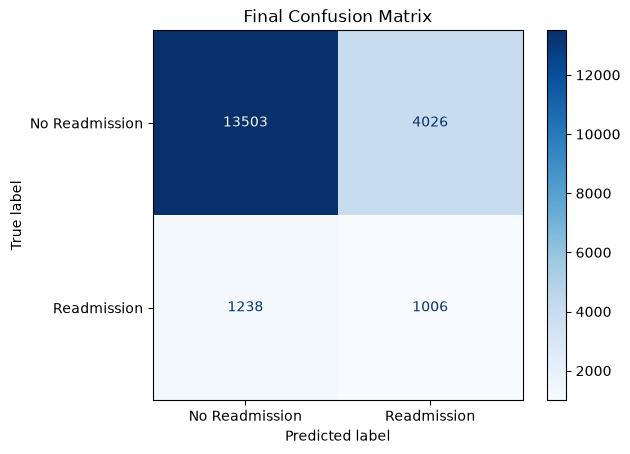

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred := (stacking_proba >= best_threshold).astype(int))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Readmission", "Readmission"]
)

disp.plot(cmap="Blues")

plt.title("Final Confusion Matrix")

plt.show()

In [13]:
import numpy as np

np.savez(
    "../data/eval_export_04.npz",
    y_test=y_test.values if hasattr(y_test, "values") else y_test,
    y_proba=stacking_proba,
    best_threshold=best_threshold,
)
print("Exported: ../data/eval_export_04.npz")

Exported: ../data/eval_export_04.npz
